
# Homework 4 — Vol Surface and Greeks

## Numerical Greeks Using Finite Differences

**Objective:** Compare analytical and numerical Delta and Gamma for European options using finite difference methods.

The numerical methods considered are:

- Forward difference
- Backward difference
- Central difference

Two bump size conventions are implemented:

- Absolute bumping
- Relative bumping

## Implementation and Testing

The pricing library was extended to support all six combinations of finite difference method and bump size convention for Delta and Gamma.

The implementation was validated using `pytest`.

**Test result: 12 passed, 0 failed.**

The initial tests use synthetic market data with a constant volatility of 20%.

## Numerical Error Analysis

We compare the numerical Greeks with their analytical values for different bump sizes.

The goal is to investigate numerical accuracy and recommend suitable bump sizes for each method.


In [1]:

# Homework 4 - Setup and analytical Greeks

import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Find our Homework 4 library
library_path = None

for folder in [Path.cwd(), *Path.cwd().parents]:
    for candidate in [
        folder / "homework4_library",
        folder / "homeworks" / "83721eb" / "homeworks" / "homework4_library"
    ]:
        if (candidate / "pricer.py").exists():
            library_path = candidate.resolve()
            break
    if library_path is not None:
        break

if library_path is None:
    raise FileNotFoundError("homework4_library not found")

sys.path.insert(0, str(library_path))

from enums import (
    Stock, PutCallFwd, LongShort,
    GreekMethod, FiniteMethod, BumpSizeMethod
)
from market_data import MarketData, VolGrid
from model import BSVolModel
from contract import EuropeanContract
from pricer import EuropeanAnalyticPricer, Params

# Synthetic market data for this experiment
underlying = Stock.BLUECHIP_BANK

points = np.array([
    [80.0, 0.5],
    [120.0, 0.5],
    [80.0, 2.0],
    [120.0, 2.0]
])

volatilities = np.array([0.20, 0.20, 0.20, 0.20])

MarketData.spot = {underlying: 100.0}
MarketData.volgrid = {
    underlying: VolGrid(underlying, points, volatilities)
}
MarketData.risk_free_rate = 0.05
MarketData.is_initialized = True

# Create a European Call
model = BSVolModel(underlying)
contract = EuropeanContract(
    underlying,
    PutCallFwd.CALL,
    LongShort.LONG,
    100.0,
    1.0
)

pricer = EuropeanAnalyticPricer(contract, model, Params())

# Analytical Greeks
analytic_delta = pricer.calc_delta(GreekMethod.ANALYTIC)
analytic_gamma = pricer.calc_gamma(GreekMethod.ANALYTIC)

print("Market setup: SUCCESS")
print(f"Analytical Delta: {analytic_delta:.6f}")
print(f"Analytical Gamma: {analytic_gamma:.6f}")


Market setup: SUCCESS
Analytical Delta: 0.636831
Analytical Gamma: 0.018762


### Numerical Error Analysis — Delta and Gamma

We compare the finite difference approximations with the analytical Greeks for different bump sizes, finite difference methods, and bumping conventions.

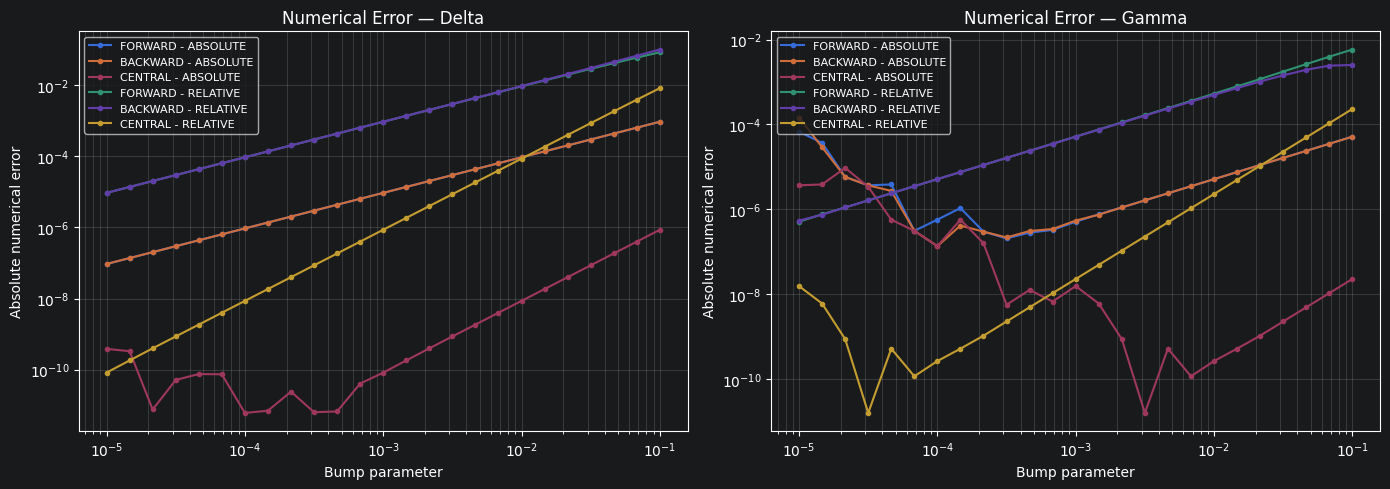

In [2]:

# Homework 4 - Numerical error comparison

bump_sizes = np.logspace(-5, -1, 25)

finite_methods = [
    FiniteMethod.FORWARD,
    FiniteMethod.BACKWARD,
    FiniteMethod.CENTRAL
]

bump_methods = [
    BumpSizeMethod.ABSOLUTE,
    BumpSizeMethod.RELATIVE
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for bump_method in bump_methods:
    for finite_method in finite_methods:

        delta_errors = []
        gamma_errors = []

        for bump in bump_sizes:
            pricer.finitemethod = finite_method
            pricer.bumpsizemethod = bump_method
            pricer.relative_bump_size = bump

            numerical_delta = pricer.calc_delta(
                GreekMethod.BUMP
            )
            numerical_gamma = pricer.calc_gamma(
                GreekMethod.BUMP
            )

            delta_errors.append(
                abs(numerical_delta - analytic_delta)
            )
            gamma_errors.append(
                abs(numerical_gamma - analytic_gamma)
            )

        label = f"{finite_method.value} - {bump_method.value}"

        axes[0].loglog(
            bump_sizes, delta_errors,
            marker="o", markersize=3, label=label
        )

        axes[1].loglog(
            bump_sizes, gamma_errors,
            marker="o", markersize=3, label=label
        )

axes[0].set_title("Numerical Error — Delta")
axes[1].set_title("Numerical Error — Gamma")

for ax in axes:
    ax.set_xlabel("Bump parameter")
    ax.set_ylabel("Absolute numerical error")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()



## Comparison Across Multiple European Options

The previous figures show the numerical errors for one European call option.

We now extend the comparison to multiple European call and put options with different strikes and maturities.

For each finite difference method and bump convention, we calculate the mean absolute error between the numerical and analytical Delta and Gamma.

This allows us to evaluate the accuracy of the methods across a wider set of contracts.


In [3]:

# Compare numerical Greeks across multiple European options

strikes = [90.0, 100.0, 110.0]
expiries = [0.5, 1.0]
option_types = [PutCallFwd.CALL, PutCallFwd.PUT]

results = []

for bump_method in BumpSizeMethod:
    for finite_method in FiniteMethod:

        delta_errors = []
        gamma_errors = []

        for strike in strikes:
            for expiry in expiries:
                for option_type in option_types:

                    contract = EuropeanContract(
                        underlying,
                        option_type,
                        LongShort.LONG,
                        strike,
                        expiry
                    )

                    p = EuropeanAnalyticPricer(
                        contract,
                        BSVolModel(underlying),
                        Params()
                    )

                    p.finitemethod = finite_method
                    p.bumpsizemethod = bump_method
                    p.relative_bump_size = 0.01

                    delta_ref = p.calc_delta(GreekMethod.ANALYTIC)
                    gamma_ref = p.calc_gamma(GreekMethod.ANALYTIC)

                    delta_num = p.calc_delta(GreekMethod.BUMP)
                    gamma_num = p.calc_gamma(GreekMethod.BUMP)

                    delta_errors.append(abs(delta_num - delta_ref))
                    gamma_errors.append(abs(gamma_num - gamma_ref))

        results.append({
            "method": finite_method.value,
            "bump": bump_method.value,
            "delta_error": np.mean(delta_errors),
            "gamma_error": np.mean(gamma_errors)
        })

print("Mean absolute errors across 12 European options")
print("-" * 75)
print(f"{'Method':<12} {'Bump':<12} {'Delta error':>16} {'Gamma error':>16}")

for row in results:
    print(
        f"{row['method']:<12} "
        f"{row['bump']:<12} "
        f"{row['delta_error']:>16.8e} "
        f"{row['gamma_error']:>16.8e}"
    )


Mean absolute errors across 12 European options
---------------------------------------------------------------------------
Method       Bump              Delta error      Gamma error
FORWARD      RELATIVE       1.01238678e-02   6.61676276e-04
BACKWARD     RELATIVE       1.02868518e-02   6.59648366e-04
CENTRAL      RELATIVE       1.10322479e-04   4.98798826e-06
FORWARD      ABSOLUTE       1.02063285e-04   6.62267259e-06
BACKWARD     ABSOLUTE       1.02079592e-04   6.62249533e-06
CENTRAL      ABSOLUTE       1.10374787e-08   5.12916057e-10



## Optimal Bump Size Selection

To compare absolute and relative bumping fairly, we use the same effective change in the underlying spot price.

For absolute bumping, the bump parameter equals h.

For relative bumping, the bump parameter equals h / S.

We test several effective bump sizes and identify the values that minimize the mean absolute numerical error across the European options.


In [4]:

# Homework 4 - Find suitable bump sizes

effective_bumps = np.logspace(-3, 0, 16)

print("Optimal effective bump sizes (within tested range)")
print("-" * 75)

for greek in ["delta", "gamma"]:
    print(f"\n{greek.upper()}")

    for finite_method in FiniteMethod:
        for bump_method in BumpSizeMethod:

            mean_errors = []

            for h in effective_bumps:
                errors = []

                for strike in strikes:
                    for expiry in expiries:
                        for option_type in option_types:

                            model = BSVolModel(underlying)

                            contract = EuropeanContract(
                                underlying,
                                option_type,
                                LongShort.LONG,
                                strike,
                                expiry
                            )

                            p = EuropeanAnalyticPricer(
                                contract, model, Params()
                            )

                            p.finitemethod = finite_method
                            p.bumpsizemethod = bump_method

                            # Same effective spot bump
                            if bump_method == BumpSizeMethod.ABSOLUTE:
                                p.relative_bump_size = h
                            else:
                                p.relative_bump_size = h / model.spot

                            calc = getattr(p, f"calc_{greek}")

                            analytical = calc(GreekMethod.ANALYTIC)
                            numerical = calc(GreekMethod.BUMP)

                            errors.append(abs(numerical - analytical))

                mean_errors.append(np.mean(errors))

            best_index = np.argmin(mean_errors)

            print(
                f"{finite_method.value:<9} "
                f"{bump_method.value:<9} | "
                f"h = {effective_bumps[best_index]:.6f} | "
                f"error = {mean_errors[best_index]:.3e}"
            )


Optimal effective bump sizes (within tested range)
---------------------------------------------------------------------------

DELTA
FORWARD   RELATIVE  | h = 0.001000 | error = 1.021e-05
FORWARD   ABSOLUTE  | h = 0.001000 | error = 1.021e-05
BACKWARD  RELATIVE  | h = 0.001000 | error = 1.021e-05
BACKWARD  ABSOLUTE  | h = 0.001000 | error = 1.021e-05
CENTRAL   RELATIVE  | h = 0.001000 | error = 1.086e-10
CENTRAL   ABSOLUTE  | h = 0.001000 | error = 1.086e-10

GAMMA
FORWARD   RELATIVE  | h = 0.001000 | error = 6.645e-07
FORWARD   ABSOLUTE  | h = 0.001000 | error = 6.645e-07
BACKWARD  RELATIVE  | h = 0.001000 | error = 6.716e-07
BACKWARD  ABSOLUTE  | h = 0.001000 | error = 6.716e-07
CENTRAL   RELATIVE  | h = 0.006310 | error = 3.257e-10
CENTRAL   ABSOLUTE  | h = 0.006310 | error = 3.257e-10



## Results and Conclusion

In this homework, we implemented and compared three finite difference methods: forward, backward, and central differences.

Both absolute and relative bumping were tested for the numerical calculation of Delta and Gamma.

### Main Findings

The central difference method produced the smallest numerical errors in our experiments.

Across 12 European call and put options, the best results within the tested bump-size range were:

- **Delta:** Central difference with an effective bump size of 0.001, giving a mean absolute error of approximately 1.086 × 10⁻¹⁰.
- **Gamma:** Central difference with an effective bump size of 0.006310, giving a mean absolute error of approximately 3.257 × 10⁻¹⁰.

Absolute and relative bumping gave equivalent results when the same effective change in the underlying spot price was used.

### Recommended Bump Sizes

For the tested European options, we recommend using the central difference method with:

- An effective spot bump of 0.001 for Delta.
- An effective spot bump of approximately 0.0063 for Gamma.

These values minimize the mean absolute errors within our tested range and should not be interpreted as universally optimal.

Very small bump sizes may introduce floating-point round-off errors, especially for Gamma, while large bump sizes increase truncation errors.

### Final Conclusion

Central finite differences provide accurate numerical approximations of analytical Delta and Gamma.

The experiments demonstrate that choosing an appropriate bump size is important for numerical stability and accuracy.

All 12 unit tests passed using synthetic market data with a constant volatility of 20%.
